In [9]:
import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
import kagglehub


# filtering

BASE_DIR = r"C:\Users\sanju\.cache\kagglehub\datasets\andrewmvd\ocular-disease-recognition-odir5k\versions\2"
IMG_DIR = os.path.join(BASE_DIR, "preprocessed_images") 
CSV_PATH = os.path.join(BASE_DIR, "full_df.csv")

df = pd.read_csv(CSV_PATH)
data = []

for _, row in df.iterrows():
    if row['H'] == 1:
        label = 'Hypertension'
        is_mixed = row[['D','G','C','A','M','O']].sum() > 0
    elif row['N'] == 1:
        label = 'Normal'
        is_mixed = False
    else:
        continue


    # Process Both Eyes
    for side, filename_col in [('Left', 'Left-Fundus'), ('Right', 'Right-Fundus')]:
        filepath = os.path.join(IMG_DIR, row[filename_col])

        # Only add if file exists
        if os.path.exists(filepath):
            data.append({
                'Patient_ID': row['ID'],
                'filename': row[filename_col],
                'filepath': filepath,
                'label': label,
                'is_mixed': is_mixed, # True if they have comorbidities
                'sex': row['Patient Sex'],
                'age': row['Patient Age']
            })


df_audit = pd.DataFrame(data)
print(f"Total Images for Analysis: {len(df_audit)}")
print(df_audit['label'].value_counts())



Total Images for Analysis: 4546
label
Normal          4143
Hypertension     403
Name: count, dtype: int64


In [10]:
# stage 1 - physical audit
# check for resolution, black border and green channel

widths = []
heights = []
fill_factors = []
green_vars = []
blur_scores = []

for idx, row in tqdm(df_audit.iterrows(), total=len(df_audit)):
    img = cv2.imread(row['filepath'])

    if img is None:
        widths.append(0); heights.append(0); fill_factors.append(0); green_vars.append(0)
        continue 

    # resolution
    h, w, _ = img.shape
    widths.append(w)
    heights.append(h)


    # black border analysis
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(gray, cv2.COLOR_RGB2GRAY)
    tissue_pixels = np.count_nonzero(gray > 10)
    total_pixels = h * w
    fill_factors.append(tissue_pixels / total_pixels)

    
    # green channel variance
    green_channel = img[:, :, 1]
    green_vars.append(np.std(green_channel))

    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    blur_scores.append(laplacian_var)


df_audit['width'] = widths
df_audit['heights'] = heights
df_audit['fill_factor'] = fill_factors
df_audit['green_std'] = green_vars
df_audit['blur_score'] = blur_scores






100%|██████████| 4546/4546 [00:24<00:00, 185.80it/s]


C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='fill_factor', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='green_std', ax=axes[2], palette={'Normal':'green', 'Hypertension':'red'})


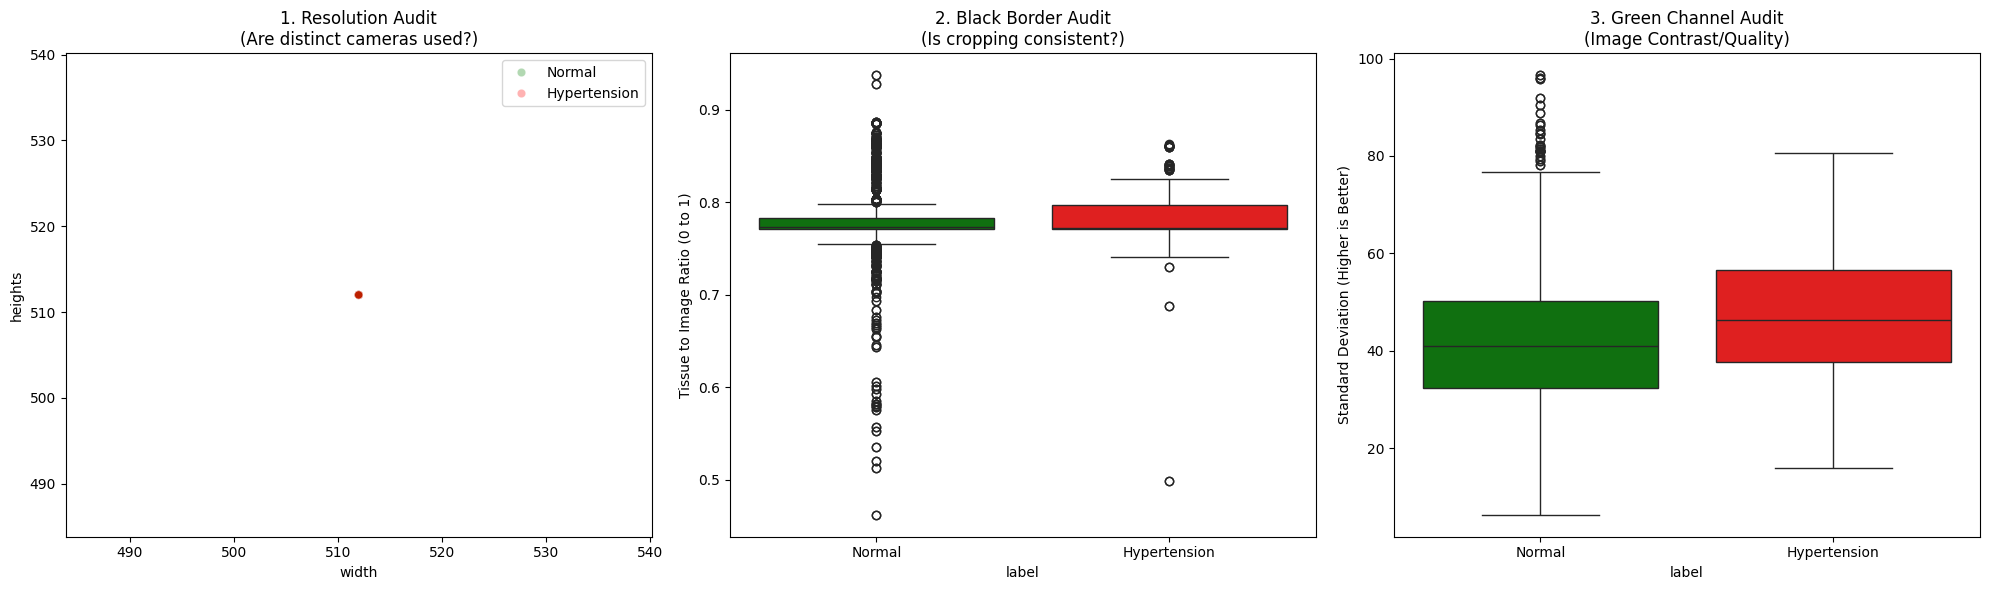

C:\Users\arnav\AppData\Local\Temp\ipykernel_1636\3492987520.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label', y='blur_score', palette={'Normal':'green', 'Hypertension':'red'})


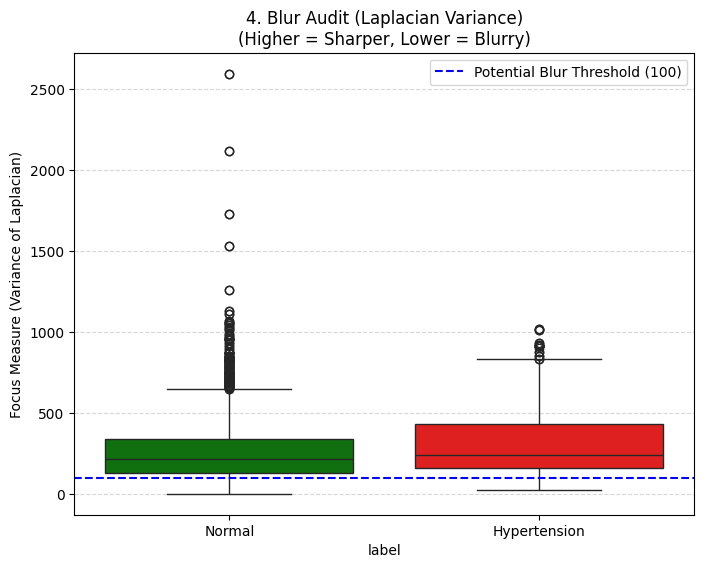


1. Camera Consistency: Found 1 different image resolutions.
   width  heights  count
0    512      512   4546

2. Image Quality (Green Variance):
   Normal Avg: 42.09
   Hypertension Avg: 46.89
   ✅ PASS: Image quality is comparable.


In [3]:
# visualisation

import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# width vs height
sns.scatterplot(data=df_audit, x='width', y='heights', hue='label', alpha=0.3, ax=axes[0], palette={'Normal':'green', 'Hypertension':'red'})
axes[0].set_title("1. Resolution Audit\n(Are distinct cameras used?)")
axes[0].legend(loc='upper right')


# black border analysis
sns.boxplot(data=df_audit, x='label', y='fill_factor', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
axes[1].set_title("2. Black Border Audit\n(Is cropping consistent?)")
axes[1].set_ylabel("Tissue to Image Ratio (0 to 1)")


# green channel variance
sns.boxplot(data=df_audit, x='label', y='green_std', ax=axes[2], palette={'Normal':'green', 'Hypertension':'red'})
axes[2].set_title("3. Green Channel Audit\n(Image Contrast/Quality)")
axes[2].set_ylabel("Standard Deviation (Higher is Better)")

plt.tight_layout()
plt.show()

# blur

plt.figure(figsize=(8, 6))

# Plot the Blur Score
sns.boxplot(data=df_audit, x='label', y='blur_score', palette={'Normal':'green', 'Hypertension':'red'})

plt.title("4. Blur Audit (Laplacian Variance)\n(Higher = Sharper, Lower = Blurry)")
plt.ylabel("Focus Measure (Variance of Laplacian)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add a reference line for "Too Blurry"
# Note: This threshold varies by dataset, but <100 is often a good starting point for finding garbage.
plt.axhline(y=100, color='blue', linestyle='--', label='Potential Blur Threshold (100)')
plt.legend()

plt.show()



# summary
unique_sizes = df_audit.groupby(['width', 'heights']).size().reset_index(name='count')
print(f"\n1. Camera Consistency: Found {len(unique_sizes)} different image resolutions.")
print(unique_sizes.sort_values('count', ascending=False).head(3))

# green channel difference
mean_norm_g = df_audit[df_audit['label']=='Normal']['green_std'].mean()
mean_hyper_g = df_audit[df_audit['label']=='Hypertension']['green_std'].mean()
print(f"\n2. Image Quality (Green Variance):")
print(f"   Normal Avg: {mean_norm_g:.2f}")
print(f"   Hypertension Avg: {mean_hyper_g:.2f}")
if abs(mean_norm_g - mean_hyper_g) > 5:
    print("   ⚠️ FLAG: Significant quality difference detected between classes.")
else:
    print("   ✅ PASS: Image quality is comparable.")








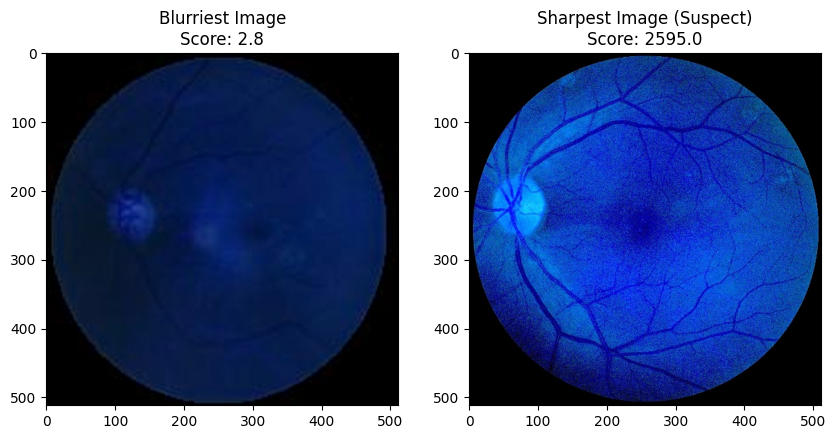

In [5]:
# blur detection

# 1. Get the indices of the extremes
worst_blur_idx = df_audit['blur_score'].idxmin() # The blurriest image
weirdest_sharp_idx = df_audit['blur_score'].idxmax() # The sharpest image (likely artifact)

# 2. Load them
img_blur = cv2.imread(df_audit.loc[worst_blur_idx, 'filepath'])
img_sharp = cv2.imread(df_audit.loc[weirdest_sharp_idx, 'filepath'])

# 3. Show them
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img_blur)
ax[0].set_title(f"Blurriest Image\nScore: {df_audit.loc[worst_blur_idx, 'blur_score']:.1f}")

ax[1].imshow(img_sharp)
ax[1].set_title(f"Sharpest Image (Suspect)\nScore: {df_audit.loc[weirdest_sharp_idx, 'blur_score']:.1f}")

plt.show()


In [9]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(test_size=0.20, n_splits=1, random_state=42)

split = splitter.split(df_audit, groups=df_audit['Patient_ID'])
train_inds, test_inds = next(split)

train_df_audit = df_audit.iloc[train_inds].copy()
test_df_audit = df_audit.iloc[test_inds].copy()

train_patients = set(train_df_audit['Patient_ID'])
test_patients = set(test_df_audit['Patient_ID'])
overlap = train_patients.intersection(test_patients)

assert len(overlap) == 0, f"CRITICAL FAILURE: Found {len(overlap)} patients in both sets!"
print(f"✅ Success! Split complete.")
print(f"   Train Patients: {len(train_patients)} | Train Images: {len(train_df_audit)}")
print(f"   Test Patients:  {len(test_patients)} | Test Images:  {len(test_df_audit)}")


✅ Success! Split complete.
   Train Patients: 946 | Train Images: 3628
   Test Patients:  237 | Test Images:  918


In [ ]:
def check_laterality(filepath, label_side):
    """
    Returns True if the bright spot matches the label (Left/Right).
    Returns False if they disagree.
    """

    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        return False
    
  
    img_blur = cv2.GaussianBlur(img, (21, 21), 0)


    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(img_blur)
    bright_x = max_loc[0]
    width = img.shape[1]
    

    detected_side = 'Left' if bright_x > (width / 2) else 'Right'
    
    
    if label_side in ['Left', 'Left-Fundus']:
        return detected_side == 'Left'
    elif label_side in ['Right', 'Right-Fundus']:
        return detected_side == 'Right'
    
    return True

mismatches = []

for idx, row in tqdm(df_audit.iterrows(), total=len(df_audit)):
  
    side_label = 'Left' if 'Left' in row['filename'] else 'Right'
    
    if not check_laterality(row['filepath'], side_label):
        mismatches.append(idx)

print(f"\n🔍 Check Complete.")
print(f"   Total Mismatches Found: {len(mismatches)}")


if len(mismatches) > 0:
    print("   ⚠️ WARNING: The following images might be labeled wrong (or inverted):")
    print(df_audit.loc[mismatches, ['Patient_ID', 'filename']])



100%|██████████| 4546/4546 [00:05<00:00, 838.68it/s]


🔍 Check Complete.
   Total Mismatches Found: 2330
   ⚠️ WARNING: The following images might be labeled wrong (or inverted):
      Patient_ID        filename
1              1     1_right.jpg
3              8     8_right.jpg
4             11     11_left.jpg
5             11    11_right.jpg
7             23    23_right.jpg
...          ...             ...
4535        4579  4579_right.jpg
4537        4581  4581_right.jpg
4539        4591  4591_right.jpg
4541        4592  4592_right.jpg
4543        4637  4637_right.jpg

[2330 rows x 2 columns]


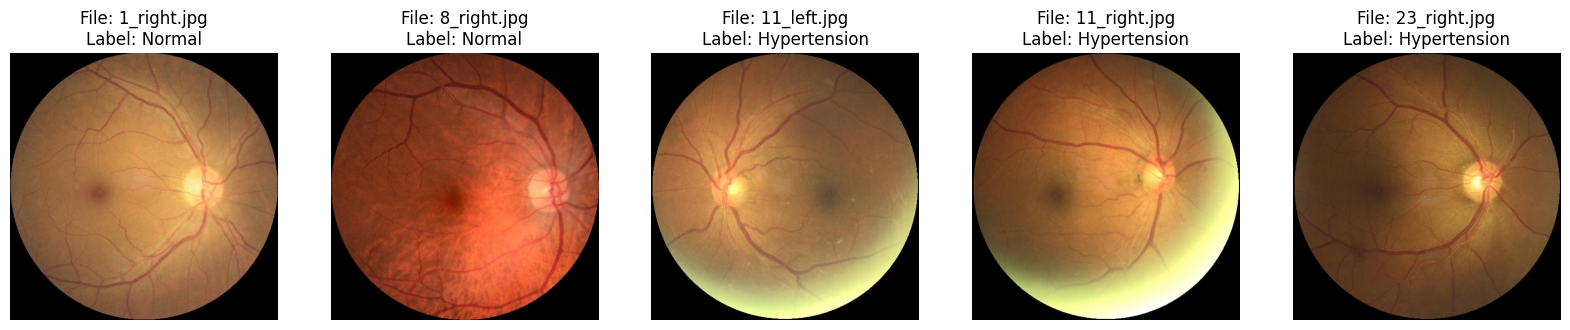

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, idx in enumerate(mismatches[:5]):
    row = df_audit.loc[idx]
    img = cv2.imread(row['filepath'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
    axes[i].imshow(img)
    axes[i].set_title(f"File: {row['filename']}\nLabel: {row['label']}")
    axes[i].axis('off')
plt.show()

Columns in df_audit: ['Patient_ID', 'filename', 'filepath', 'label', 'is_mixed', 'sex', 'age', 'width', 'heights', 'fill_factor', 'green_std', 'blur_score']

--- 1.1 Age Bias Check (age) ---


C:\Users\sanju\AppData\Local\Temp\ipykernel_31224\4137443239.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=LABEL_COL, y=AGE_COL, data=df_audit, palette={'Normal':'green', 'Hypertension':'red'})


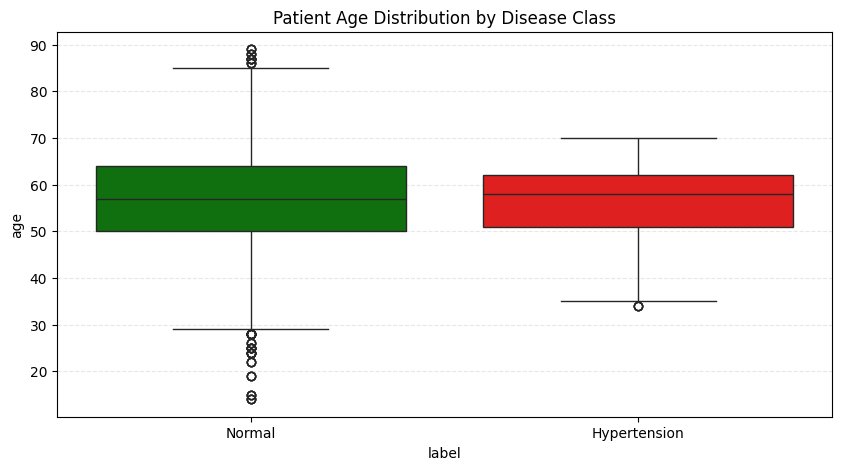

📊 Age Statistics:
   - Normal Median: 57.0
   - Hypertension Median: 58.0
   - P-Value: 2.2285e-01
   ✅ PASS: Age is balanced.

--- 1.2 Sex Bias Check (sex) ---


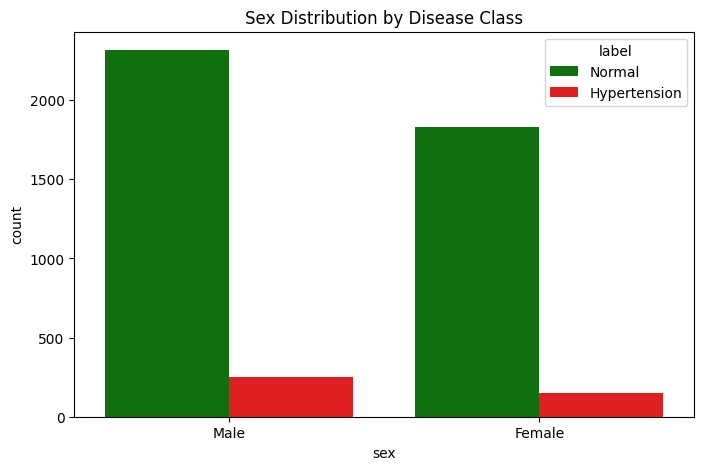

📊 Sex Statistics (P-Value): 1.5779e-02
   ⚠️ SIGNIFICANT IMBALANCE detected in Sex distribution.

--- 2. Computing Average Images (Ghosting Check) ---


Averaging: 100%|██████████| 403/403 [00:01<00:00, 218.91it/s]


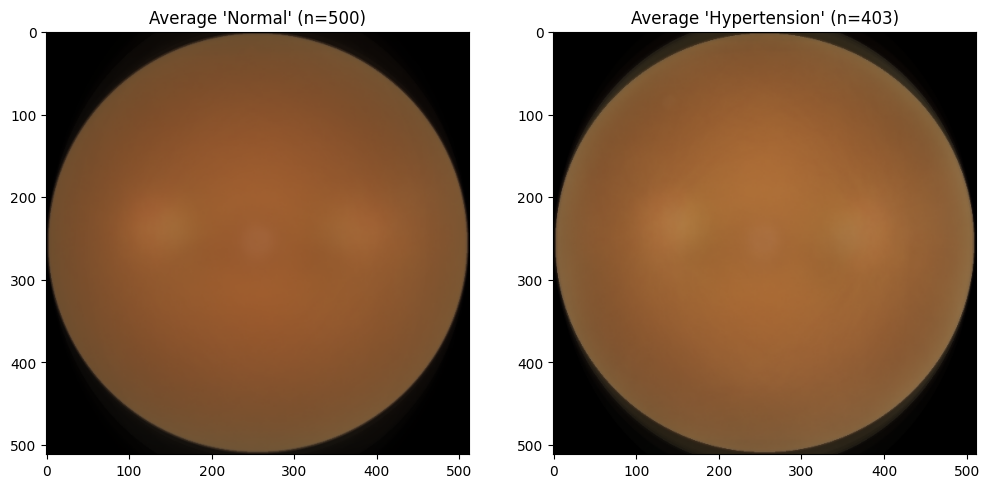


--- 3. UMAP Projection (Feature Space) ---
Extracting features for 800 images...


100%|██████████| 800/800 [01:24<00:00,  9.45it/s]
c:\Users\sanju\OneDrive\Documents\Large Group Project\Project-Retinexis\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


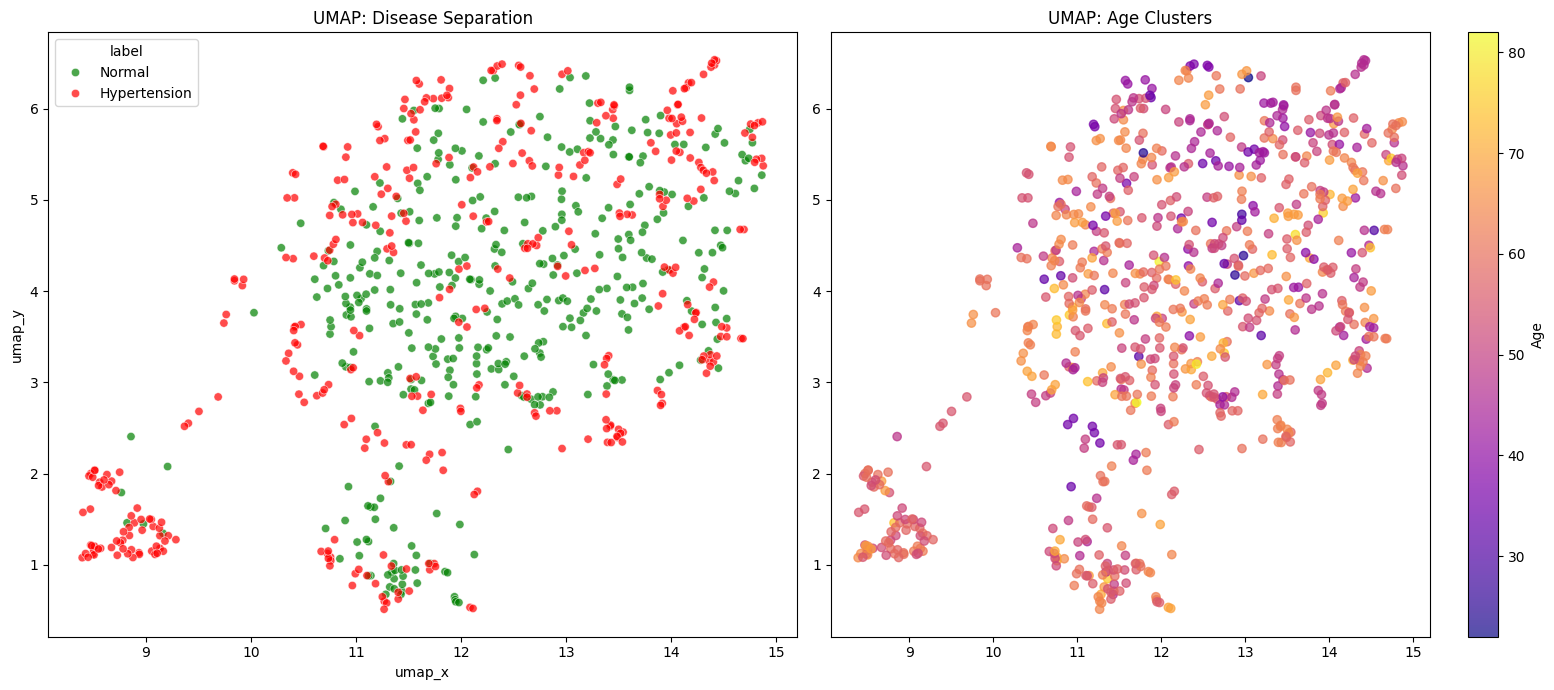

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, chi2_contingency
import cv2
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image
import umap
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

# --- CONFIGURATION: Check your column names here ---
AGE_COL = 'age'            # or 'Patient Age'
SEX_COL = 'sex'    # or 'patient_sex' or 'Sex'
LABEL_COL = 'label'

# Quick check to ensure columns exist
print(f"Columns in df_audit: {df_audit.columns.tolist()}")
if SEX_COL not in df_audit.columns:
    print(f"⚠️ WARNING: Could not find '{SEX_COL}'. Please update the SEX_COL variable above.")

# ==============================================================================
# PART 1: CLINICAL BIAS CHECKS (Age & Sex)
# ==============================================================================

# 1.1 Age Distribution Analysis
print(f"\n--- 1.1 Age Bias Check ({AGE_COL}) ---")
plt.figure(figsize=(10, 5))
sns.boxplot(x=LABEL_COL, y=AGE_COL, data=df_audit, palette={'Normal':'green', 'Hypertension':'red'})
plt.title('Patient Age Distribution by Disease Class')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

# Statistical Test (Mann-Whitney U)
# We drop NaNs to avoid errors
age_normal = df_audit[df_audit[LABEL_COL]=='Normal'][AGE_COL].dropna()
age_hyper = df_audit[df_audit[LABEL_COL]=='Hypertension'][AGE_COL].dropna()

if len(age_normal) > 0 and len(age_hyper) > 0:
    stat, p_val = mannwhitneyu(age_normal, age_hyper)
    print(f"📊 Age Statistics:")
    print(f"   - Normal Median: {age_normal.median():.1f}")
    print(f"   - Hypertension Median: {age_hyper.median():.1f}")
    print(f"   - P-Value: {p_val:.4e}")
    if p_val < 0.05:
        print("   ⚠️ SIGNIFICANT DIFFERENCE. The model might use Age as a shortcut.")
    else:
        print("   ✅ PASS: Age is balanced.")

# 1.2 Sex Distribution Analysis
if SEX_COL in df_audit.columns:
    print(f"\n--- 1.2 Sex Bias Check ({SEX_COL}) ---")
    plt.figure(figsize=(8, 5))
    sns.countplot(x=SEX_COL, hue=LABEL_COL, data=df_audit, palette={'Normal':'green', 'Hypertension':'red'})
    plt.title('Sex Distribution by Disease Class')
    plt.show()

    # Statistical Test (Chi-Square)
    ct_sex = pd.crosstab(df_audit[SEX_COL], df_audit[LABEL_COL])
    if not ct_sex.empty:
        chi2, p_val, dof, expected = chi2_contingency(ct_sex)
        print(f"📊 Sex Statistics (P-Value): {p_val:.4e}")
        if p_val < 0.05:
            print("   ⚠️ SIGNIFICANT IMBALANCE detected in Sex distribution.")
        else:
            print("   ✅ PASS: Sex is balanced.")


# ==============================================================================
# PART 2: ARTIFACT SCAN (Average Image)
# ==============================================================================
print("\n--- 2. Computing Average Images (Ghosting Check) ---")

def compute_avg_image(img_paths):
    avg_img = None
    count = 0
    # Process in a loop
    for path in tqdm(img_paths, desc="Averaging"):
        img = cv2.imread(path)
        if img is None: continue
        # Resize to ensure they stack correctly
        img = cv2.resize(img, (512, 512))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(float)
        
        if avg_img is None:
            avg_img = img
        else:
            avg_img += img
        count += 1
    
    if count == 0: return None
    return (avg_img / count).astype(np.uint8)

# Sample 500 images per class (or all if <500)
# We perform the scan only on valid files
s_norm = df_audit[df_audit[LABEL_COL]=='Normal'].sample(n=min(500, len(df_audit[df_audit[LABEL_COL]=='Normal'])), random_state=42)
s_hyper = df_audit[df_audit[LABEL_COL]=='Hypertension'].sample(n=min(500, len(df_audit[df_audit[LABEL_COL]=='Hypertension'])), random_state=42)

avg_norm = compute_avg_image(s_norm['filepath'].values)
avg_hyper = compute_avg_image(s_hyper['filepath'].values)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
if avg_norm is not None:
    ax[0].imshow(avg_norm)
    ax[0].set_title(f"Average 'Normal' (n={len(s_norm)})")
if avg_hyper is not None:
    ax[1].imshow(avg_hyper)
    ax[1].set_title(f"Average 'Hypertension' (n={len(s_hyper)})")
plt.show()


# ==============================================================================
# PART 3: UMAP MANIFOLD (The Deep Dive)
# ==============================================================================
print("\n--- 3. UMAP Projection (Feature Space) ---")

# 3.1 Load ResNet50 (Feature Extractor)
model = ResNet50(weights='imagenet', include_top=False, pooling='avg')

# 3.2 Prepare Data Subset (Balanced if possible)
# We take up to 400 from each class to keep the plot readable and fast
subset = pd.concat([
    df_audit[df_audit[LABEL_COL]=='Normal'].sample(n=400, random_state=42),
    df_audit[df_audit[LABEL_COL]=='Hypertension'].sample(n=min(400, len(df_audit[df_audit[LABEL_COL]=='Hypertension'])), random_state=42)
])

print(f"Extracting features for {len(subset)} images...")

# 3.3 Extract Features
features = []
valid_indices = []

for idx, row in tqdm(subset.iterrows(), total=len(subset)):
    try:
        img = image.load_img(row['filepath'], target_size=(224, 224))
        x = image.img_to_array(img)
        x = preprocess_input(x) # ResNet preprocessing
        x = np.expand_dims(x, axis=0)
        
        feat = model.predict(x, verbose=0)
        features.append(feat.flatten())
        valid_indices.append(idx)
    except Exception as e:
        pass

# 3.4 UMAP Reduction
if len(features) > 0:
    X = np.array(features)
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    embedding = reducer.fit_transform(StandardScaler().fit_transform(X))

    # Re-align dataframe to valid images
    plot_df = subset.loc[valid_indices].copy()
    plot_df['umap_x'] = embedding[:, 0]
    plot_df['umap_y'] = embedding[:, 1]

    # 3.5 Plotting
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Plot A: Disease Separation
    sns.scatterplot(x='umap_x', y='umap_y', hue=LABEL_COL, data=plot_df, 
                    palette={'Normal':'green', 'Hypertension':'red'}, alpha=0.7, ax=axes[0])
    axes[0].set_title('UMAP: Disease Separation')

    # Plot B: Age Confounder
    if AGE_COL in plot_df.columns:
        sc = axes[1].scatter(plot_df['umap_x'], plot_df['umap_y'], c=plot_df[AGE_COL], cmap='plasma', alpha=0.7)
        plt.colorbar(sc, ax=axes[1], label='Age')
        axes[1].set_title('UMAP: Age Clusters')

    plt.tight_layout()
    plt.show()
else:
    print("❌ Could not extract features. Check image paths.")

STAGE 3